In [1]:
# ================================================================
# AI IN BIOMEDICINE - GLIOMA SEGMENTATION
# PHASE 1 - DATASET EXPLORATION & TRAINING MANIFEST
# ================================================================
#
# Questo notebook NON esegue training.
#
# Obiettivi:
#   1. Ispezionare il dataset
#   2. Individuare pazienti, MRI e maschere
#   3. Controllare la disponibilità delle 4 modalità
#   4. Controllare la distribuzione dei centri
#   5. Ispezionare le label delle maschere
#   6. Identificare pazienti con/senza maschera
#   7. Creare split patient-level riproducibili
#   8. Creare manifest CSV per il notebook di training
#
# Split:
#   - TRAIN: pazienti con maschera
#   - VALIDATION: pazienti con maschera
#   - TEST: pazienti con maschera
#   - UNLABELED: pazienti senza maschera
#
# Per MAE:
#   training unlabeled data = TRAIN + UNLABELED
#   TEST non viene mai utilizzato nel pre-training.
#
# ================================================================

import sys
import subprocess
import importlib.util
import warnings
import re
import json
import random

from pathlib import Path
from collections import Counter

# ------------------------------------------------
# Installazione automatica delle librerie mancanti
# ------------------------------------------------

required_packages = {
    "nibabel": "nibabel",
    "openpyxl": "openpyxl",
    "sklearn": "scikit-learn"
}

for module, package in required_packages.items():

    if importlib.util.find_spec(module) is None:

        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            package
        ])

# ------------------------------------------------
# Import
# ------------------------------------------------

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

print("=" * 70)
print("GLIOMA DATASET - PHASE 1")
print("=" * 70)

GLIOMA DATASET - PHASE 1


In [3]:
# ================================================================
# 1. CONFIGURATION
# ================================================================

# -----------------------------
# Dataset paths
# -----------------------------

METADATA_PATH = Path(
    "/kaggle/input/datasets/laurapitton/metadata-excel/training_metadata.xlsx"
)

IMAGES_DIR = Path(
    "/kaggle/input/datasets/laurapitton/training-images/Training_images"
)

# -----------------------------
# Output
# -----------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/phase1_reports"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# -----------------------------
# Metadata columns
# -----------------------------

PATIENT_ID_COLUMN = "ID"
COHORT_COLUMN = "Cohort ID"

# -----------------------------
# MRI modalities
# -----------------------------

MODALITIES = [
    "FLAIR",
    "T1",
    "T1CE",
    "T2"
]

# -----------------------------
# Reproducibility
# -----------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# -----------------------------
# Dataset split
# -----------------------------

TEST_SIZE = 0.15
VAL_SIZE = 0.15

# -----------------------------
# Visualization
# -----------------------------

MAX_VISUALIZATION_PATIENTS = 3

# -----------------------------
# Label mapping
# -----------------------------

LABEL_MAPPING = {
    0: 0,   # background
    1: 1,   # necrotic core
    2: 2,   # FLAIR signal hyperintensity
    4: 3    # enhancing tumor
}

LABEL_NAMES = {
    0: "background",
    1: "necrotic_core",
    2: "flair_hyperintensity",
    3: "enhancing_tumor"
}

print("Configuration loaded.")
print("Seed:", SEED)
print("Output directory:", OUTPUT_DIR)

# ================================================================
# 2. CHECK INPUT PATHS
# ================================================================

print("\nChecking input paths...")

if not METADATA_PATH.is_file():

    raise FileNotFoundError(
        f"Metadata file not found:\n{METADATA_PATH}"
    )

if not IMAGES_DIR.is_dir():

    raise FileNotFoundError(
        f"Images directory not found:\n{IMAGES_DIR}"
    )

print("\n✓ Metadata found:")
print(METADATA_PATH)

print("\n✓ Images directory found:")
print(IMAGES_DIR)

print("\n✓ Output directory:")
print(OUTPUT_DIR)

# ================================================================
# 3. READ METADATA
# ================================================================

metadata = pd.read_excel(
    METADATA_PATH
)

print("Metadata shape:", metadata.shape)

print("\nMetadata columns:")
for column in metadata.columns:
    print(" -", column)

# Controlliamo che le colonne fondamentali esistano

required_metadata_columns = [
    PATIENT_ID_COLUMN,
    COHORT_COLUMN
]

missing_columns = [
    col
    for col in required_metadata_columns
    if col not in metadata.columns
]

if missing_columns:

    raise ValueError(
        f"Missing metadata columns: {missing_columns}"
    )

print("\nFirst rows:")
display(metadata.head())

Configuration loaded.
Seed: 42
Output directory: /kaggle/working/phase1_reports

Checking input paths...

✓ Metadata found:
/kaggle/input/datasets/laurapitton/metadata-excel/training_metadata.xlsx

✓ Images directory found:
/kaggle/input/datasets/laurapitton/training-images/Training_images

✓ Output directory:
/kaggle/working/phase1_reports
Metadata shape: (1384, 3)

Metadata columns:
 - ID
 - MGMT value
 - Cohort ID

First rows:


,ID,MGMT value,Cohort ID
0,1,NaN,1
1,2,NaN,1
2,3,0.0,1
3,4,NaN,1
4,5,NaN,2


In [4]:
# ================================================================
# 4. NORMALIZE PATIENT IDS
# ================================================================

def normalize_patient_id(value):

    if pd.isna(value):
        return None

    value = str(value).strip()

    # Excel può trasformare 001 in 1.0
    if value.endswith(".0"):
        value = value[:-2]

    match = re.fullmatch(
        r"(?:patient[_\-\s]?)?0*(\d+)",
        value,
        flags=re.IGNORECASE
    )

    if match:

        return str(
            int(match.group(1))
        )

    return value.lower()


metadata["patient_key"] = (
    metadata[PATIENT_ID_COLUMN]
    .apply(normalize_patient_id)
)

metadata["cohort_clean"] = (
    metadata[COHORT_COLUMN]
    .astype("string")
    .str.strip()
)

print("Unique patient IDs in metadata:",
      metadata["patient_key"].nunique())

duplicate_metadata_ids = metadata[
    metadata["patient_key"].duplicated(
        keep=False
    )
]

print(
    "Duplicated patient IDs in metadata:",
    len(duplicate_metadata_ids)
)

if len(duplicate_metadata_ids):

    display(
        duplicate_metadata_ids.head(20)
    )

# ================================================================
# 5. CENTER / COHORT DISTRIBUTION
# ================================================================

cohort_distribution = (
    metadata[COHORT_COLUMN]
    .value_counts(dropna=False)
    .rename_axis("Cohort_ID")
    .reset_index(
        name="number_of_patients"
    )
)

print(
    "Number of centers:",
    metadata[COHORT_COLUMN].nunique(
        dropna=True
    )
)

print("\nPatients per center:")

display(cohort_distribution)

print(
    "\nPatients with missing Cohort ID:",
    metadata[COHORT_COLUMN].isna().sum()
)

# ================================================================
# 6. FIND PATIENT FOLDERS
# ================================================================

patient_dirs = sorted(
    [
        p
        for p in IMAGES_DIR.iterdir()
        if p.is_dir()
    ],
    key=lambda p: p.name
)

if not patient_dirs:

    raise RuntimeError(
        "No patient folders found."
    )

print(
    "Number of patient folders:",
    len(patient_dirs)
)

print("\nFirst 15 patient folders:")

for p in patient_dirs[:15]:
    print(" -", p.name)

Unique patient IDs in metadata: 1384
Duplicated patient IDs in metadata: 0
Number of centers: 8

Patients per center:


,Cohort_ID,number_of_patients
0,8,416
1,4,401
2,7,267
3,5,123
4,6,108
5,2,37
6,3,28
7,1,4



Patients with missing Cohort ID: 0
Number of patient folders: 1384

First 15 patient folders:
 - 1
 - 10
 - 1000
 - 1001
 - 1002
 - 1003
 - 1004
 - 1005
 - 1006
 - 1007
 - 1008
 - 1009
 - 101
 - 1010
 - 1011


In [7]:
# ================================================================
# 7. FILE PATTERNS
# ================================================================

# ------------------------------------------------
# MRI patterns
# ------------------------------------------------

MRI_PATTERNS = {

    "FLAIR": [
        re.compile(
            r"^flair\.nii(\.gz)?$",
            re.I
        ),
        re.compile(
            r".*_brain_flair\.nii(\.gz)?$",
            re.I
        )
    ],

    "T1": [
        re.compile(
            r"^t1\.nii(\.gz)?$",
            re.I
        ),
        re.compile(
            r".*_brain_t1\.nii(\.gz)?$",
            re.I
        )
    ],

    "T1CE": [
        re.compile(
            r"^t1ce\.nii(\.gz)?$",
            re.I
        ),
        re.compile(
            r".*_brain_t1ce\.nii(\.gz)?$",
            re.I
        )
    ],

    "T2": [
        re.compile(
            r"^t2\.nii(\.gz)?$",
            re.I
        ),
        re.compile(
            r".*_brain_t2\.nii(\.gz)?$",
            re.I
        )
    ]
}


# ------------------------------------------------
# Segmentation mask patterns
# ------------------------------------------------

MASK_PATTERNS = [

    re.compile(
        r"^seg(?:_new)?\.nii(\.gz)?$",
        re.I
    ),

    re.compile(
        r".*_seg(?:_new)?\.nii(\.gz)?$",
        re.I
    )
]


print("MRI patterns configured.")
print("Mask patterns configured.")

# ================================================================
# 8. FILE DISCOVERY FUNCTIONS
# ================================================================

def matches_patterns(
    filename,
    patterns
):

    return any(
        pattern.fullmatch(filename)
        for pattern in patterns
    )


def find_files(
    patient_dir,
    patterns
):

    matches = []

    for path in patient_dir.rglob("*"):

        if not path.is_file():
            continue

        if matches_patterns(
            path.name,
            patterns
        ):
            matches.append(path)

    return sorted(
        set(matches),
        key=lambda p: str(p).lower()
    )


def find_mask_files(
    patient_dir
):

    """
    Cerca le maschere in modo ricorsivo.

    Supporta:
        seg.nii
        seg.nii.gz
        seg_new.nii
        seg_new.nii.gz
        *_seg.nii
        *_seg.nii.gz
        *_seg_new.nii
        *_seg_new.nii.gz

    Inoltre gestisce il caso in cui una directory
    si chiami seg.nii o seg.nii.gz e contenga
    effettivamente un file NIfTI.
    """

    matches = find_files(
        patient_dir,
        MASK_PATTERNS
    )

    # Caso particolare:
    # directory chiamata seg.nii / seg.nii.gz

    for directory in patient_dir.rglob("*"):

        if not directory.is_dir():
            continue

        if re.fullmatch(
            r"seg\.nii(\.gz)?",
            directory.name,
            re.I
        ):

            for path in directory.rglob("*"):

                if (
                    path.is_file()
                    and re.search(
                        r"\.nii(\.gz)?$",
                        path.name,
                        re.I
                    )
                ):

                    matches.append(path)

    return sorted(
        set(matches),
        key=lambda p: str(p).lower()
    )


print("File discovery functions ready.")

# ================================================================
# 9. BUILD PATIENT INVENTORY
# ================================================================

print("Building patient inventory...\n")

patient_records = []
file_records = []
duplicate_records = []
empty_records = []

for patient_idx, patient_dir in enumerate(
    patient_dirs,
    start=1
):

    if patient_idx % 100 == 0:

        print(
            f"Scanned {patient_idx}/{len(patient_dirs)} patients"
        )

    patient_key = normalize_patient_id(
        patient_dir.name
    )

    record = {
        "patient_folder": patient_dir.name,
        "patient_key": patient_key
    }

    # ============================================================
    # MRI
    # ============================================================

    for modality in MODALITIES:

        matches = find_files(
            patient_dir,
            MRI_PATTERNS[modality]
        )

        record[modality] = (
            len(matches) > 0
        )

        record[f"{modality}_path"] = (
            str(matches[0])
            if matches
            else None
        )

        record[f"{modality}_file_count"] = (
            len(matches)
        )

        # Multiple candidates
        if len(matches) > 1:

            duplicate_records.append({
                "patient_folder":
                    patient_dir.name,

                "file_type":
                    modality,

                "number_of_matches":
                    len(matches),

                "paths":
                    " | ".join(
                        map(str, matches)
                    )
            })

        # File inventory
        for idx, path in enumerate(matches):

            size_bytes = path.stat().st_size

            file_records.append({

                "patient_folder":
                    patient_dir.name,

                "patient_key":
                    patient_key,

                "file_type":
                    modality,

                "filename":
                    path.name,

                "file_path":
                    str(path),

                "size_MB":
                    round(
                        size_bytes /
                        (1024 ** 2),
                        3
                    ),

                "size_bytes":
                    size_bytes,

                "selected_for_inspection":
                    idx == 0
            })

            if size_bytes == 0:

                empty_records.append({
                    "patient_folder":
                        patient_dir.name,

                    "file_type":
                        modality,

                    "file_path":
                        str(path)
                })

    # ============================================================
    # MASK
    # ============================================================

    mask_matches = find_mask_files(
        patient_dir
    )

    record["MASK"] = (
        len(mask_matches) > 0
    )

    record["MASK_path"] = (
        str(mask_matches[0])
        if mask_matches
        else None
    )

    record["MASK_file_count"] = (
        len(mask_matches)
    )

    if len(mask_matches) > 1:

        duplicate_records.append({
            "patient_folder":
                patient_dir.name,

            "file_type":
                "MASK",

            "number_of_matches":
                len(mask_matches),

            "paths":
                " | ".join(
                    map(str, mask_matches)
                )
        })

    for idx, path in enumerate(mask_matches):

        size_bytes = path.stat().st_size

        file_records.append({

            "patient_folder":
                patient_dir.name,

            "patient_key":
                patient_key,

            "file_type":
                "MASK",

            "filename":
                path.name,

            "file_path":
                str(path),

            "size_MB":
                round(
                    size_bytes /
                    (1024 ** 2),
                    3
                ),

            "size_bytes":
                size_bytes,

            "selected_for_inspection":
                idx == 0
        })

        if size_bytes == 0:

            empty_records.append({
                "patient_folder":
                    patient_dir.name,

                "file_type":
                    "MASK",

                "file_path":
                    str(path)
            })

    # ============================================================
    # PATIENT-LEVEL FLAGS
    # ============================================================

    record["NUMBER_OF_MODALITIES"] = sum(
        bool(record[m])
        for m in MODALITIES
    )

    record["ALL_MODALITIES_PRESENT"] = all(
        bool(record[m])
        for m in MODALITIES
    )

    record["MASK_PRESENT"] = bool(
        record["MASK"]
    )

    record["COMPLETE_PATIENT"] = (
        record["ALL_MODALITIES_PRESENT"]
        and record["MASK_PRESENT"]
    )

    patient_records.append(record)


# ------------------------------------------------
# DataFrames
# ------------------------------------------------

patient_df = pd.DataFrame(
    patient_records
)

files_df = pd.DataFrame(
    file_records
)

duplicate_files_df = pd.DataFrame(
    duplicate_records
)

empty_df = pd.DataFrame(
    empty_records
)

print("\n" + "=" * 60)

print(
    "Patient folders:",
    len(patient_df)
)

print(
    "File candidates:",
    len(files_df)
)

print(
    "Patients with multiple candidates:",
    len(duplicate_files_df)
)

print(
    "Empty files:",
    len(empty_df)
)

print("=" * 60)

# ================================================================
# FIX DUPLICATE FLAIR - PATIENT 813
# ================================================================
# Il paziente 813 contiene due file FLAIR.
# Per il dataset di training ne manteniamo uno solo.
#
# ATTENZIONE:
# - il file originale NON viene cancellato da /kaggle/input
# - viene semplicemente escluso dal patient/file inventory
# - questa scelta deve rimanere coerente in tutti i manifest successivi
# ================================================================

patient_id = "813"

# Trova tutti i FLAIR del paziente 813 usando la stessa funzione
# di discovery ricorsiva usata per costruire l'inventory.
flair_files_813 = sorted(
    find_files(
        IMAGES_DIR / patient_id,
        MRI_PATTERNS["FLAIR"]
    ),
    key=lambda p: str(p).lower()
)

print(f"FLAIR files found for patient {patient_id}: {len(flair_files_813)}")

for i, path in enumerate(flair_files_813):
    print(f"{i + 1}. {path}")

if len(flair_files_813) > 1:

    # Manteniamo il primo file secondo l'ordinamento alfabetico
    selected_flair = str(flair_files_813[0])

    excluded_flairs = flair_files_813[1:]

    # ------------------------------------------------------------
    # Aggiorna patient_df
    # ------------------------------------------------------------
    mask_patient = patient_df["patient_folder"].astype(str) == patient_id

    patient_df.loc[
        mask_patient,
        "FLAIR_path"
    ] = selected_flair

    patient_df.loc[
        mask_patient,
        "FLAIR_file_count"
    ] = 1

    # ------------------------------------------------------------
    # Aggiorna files_df
    # ------------------------------------------------------------
    # Rimuove dall'inventory tutti i FLAIR di 813
    # tranne quello selezionato.
    # ------------------------------------------------------------
    files_df = files_df[
        ~(
            (files_df["patient_folder"].astype(str) == patient_id) &
            (files_df["file_type"] == "FLAIR") &
            (files_df["file_path"] != selected_flair)
        )
    ].copy()

    print("\nDuplicate FLAIR detected.")
    print(f"Kept:     {selected_flair}")

    print("Excluded:")
    for path in excluded_flairs:
        print(f"  - {path}")

else:
    print("\nNo duplicate FLAIR found.")

print("\nPatient 813 inventory updated.")

# ================================================================
# 10. MATCH PATIENTS WITH METADATA
# ================================================================

print("Matching patient folders with metadata...")

if metadata["patient_key"].duplicated().any():

    raise ValueError(
        "Duplicate patient_key values found in metadata. "
        "Resolve duplicates before creating the training manifest."
    )


patient_df = patient_df.merge(
    metadata[
        [
            "patient_key",
            COHORT_COLUMN
        ]
    ],
    on="patient_key",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMerge result:")

display(
    patient_df["_merge"]
    .value_counts()
)

unmatched_patients = patient_df[
    patient_df["_merge"] == "left_only"
].copy()

print(
    "\nImage folders without metadata:",
    len(unmatched_patients)
)

if len(unmatched_patients):

    display(
        unmatched_patients[
            [
                "patient_folder",
                "patient_key"
            ]
        ].head(20)
    )

patient_df.drop(
    columns="_merge",
    inplace=True
)

# ================================================================
# 11. MRI MODALITY COMBINATIONS
# ================================================================

patient_df["MRI_COMBINATION"] = (
    patient_df[MODALITIES]
    .apply(
        lambda row:
        " + ".join(
            modality
            for modality in MODALITIES
            if bool(row[modality])
        )
        or "NO MRI",
        axis=1
    )
)

combination_summary = (
    patient_df[
        "MRI_COMBINATION"
    ]
    .value_counts()
    .rename_axis(
        "MRI_combination"
    )
    .reset_index(
        name="number_of_patients"
    )
)

display(
    combination_summary
)

print("\nAvailability of masks for each MRI combination:")

combination_mask_summary = (
    patient_df
    .groupby(
        [
            "MRI_COMBINATION",
            "MASK"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=[False, True],
        fill_value=0
    )
    .rename(
        columns={
            False: "without_mask",
            True: "with_mask"
        }
    )
)

display(
    combination_mask_summary
)

# ================================================================
# 12. DATASET AVAILABILITY SUMMARY
# ================================================================

total_patients = len(
    patient_df
)

availability_records = []

for modality in MODALITIES + ["MASK"]:

    available = int(
        patient_df[modality].sum()
    )

    missing = (
        total_patients -
        available
    )

    availability_records.append({

        "file_type":
            modality,

        "available_patients":
            available,

        "missing_patients":
            missing,

        "availability_percentage":
            round(
                100 *
                available /
                total_patients,
                2
            )
    })

availability_df = pd.DataFrame(
    availability_records
)

display(
    availability_df
)

print("\nKey counts")

print(
    "Total patients:",
    total_patients
)

print(
    "All 4 MRI modalities:",
    int(
        patient_df[
            "ALL_MODALITIES_PRESENT"
        ].sum()
    )
)

print(
    "Patients with mask:",
    int(
        patient_df[
            "MASK"
        ].sum()
    )
)

print(
    "Complete patients:",
    int(
        patient_df[
            "COMPLETE_PATIENT"
        ].sum()
    )
)

print(
    "Patients with at least one MRI:",
    int(
        (
            patient_df[
                "NUMBER_OF_MODALITIES"
            ] > 0
        ).sum()
    )
)

# ================================================================
# 13. AVAILABILITY BY CENTER
# ================================================================

center_availability = (
    patient_df
    .groupby(
        COHORT_COLUMN,
        dropna=False
    )
    .agg(

        total_patients=(
            "patient_key",
            "size"
        ),

        FLAIR=(
            "FLAIR",
            "sum"
        ),

        T1=(
            "T1",
            "sum"
        ),

        T1CE=(
            "T1CE",
            "sum"
        ),

        T2=(
            "T2",
            "sum"
        ),

        MASK=(
            "MASK",
            "sum"
        ),

        all_four_MRI=(
            "ALL_MODALITIES_PRESENT",
            "sum"
        ),

        complete_patients=(
            "COMPLETE_PATIENT",
            "sum"
        )
    )
)

display(
    center_availability
)

MRI patterns configured.
Mask patterns configured.
File discovery functions ready.
Building patient inventory...

Scanned 100/1384 patients
Scanned 200/1384 patients
Scanned 300/1384 patients
Scanned 400/1384 patients
Scanned 500/1384 patients
Scanned 600/1384 patients
Scanned 700/1384 patients
Scanned 800/1384 patients
Scanned 900/1384 patients
Scanned 1000/1384 patients
Scanned 1100/1384 patients
Scanned 1200/1384 patients
Scanned 1300/1384 patients

Patient folders: 1384
File candidates: 6717
Patients with multiple candidates: 1
Empty files: 0
FLAIR files found for patient 813: 2
1. /kaggle/input/datasets/laurapitton/training-images/Training_images/813/flair.nii(1)/00000411_brain_flair.nii
2. /kaggle/input/datasets/laurapitton/training-images/Training_images/813/flair.nii/00000411_brain_flair.nii

Duplicate FLAIR detected.
Kept:     /kaggle/input/datasets/laurapitton/training-images/Training_images/813/flair.nii(1)/00000411_brain_flair.nii
Excluded:
  - /kaggle/input/datasets/laurap

_merge
both          1384
left_only        0
right_only       0
Name: count, dtype: int64


Image folders without metadata: 0


,MRI_combination,number_of_patients
0,FLAIR + T1 + T1CE + T2,1384



Availability of masks for each MRI combination:


MASK,without_mask,with_mask
MRI_COMBINATION,,
FLAIR + T1 + T1CE + T2,204,1180


,file_type,available_patients,missing_patients,availability_percentage
0,FLAIR,1384,0,100.00
1,T1,1384,0,100.00
2,T1CE,1384,0,100.00
3,T2,1384,0,100.00
4,MASK,1180,204,85.26



Key counts
Total patients: 1384
All 4 MRI modalities: 1384
Patients with mask: 1180
Complete patients: 1180
Patients with at least one MRI: 1384


,total_patients,FLAIR,T1,T1CE,T2,MASK,all_four_MRI,complete_patients
Cohort ID,,,,,,,,
1,4,4,4,4,4,4,4,4
2,37,37,37,37,37,33,37,33
3,28,28,28,28,28,25,28,25
4,401,401,401,401,401,348,401,348
5,123,123,123,123,123,94,123,94
6,108,108,108,108,108,65,108,65
7,267,267,267,267,267,233,267,233
8,416,416,416,416,416,378,416,378


In [6]:
# ================================================================
# 14. MASK LABEL INSPECTION
# ================================================================

print(
    "Inspecting segmentation labels..."
)

mask_records = []

global_label_counts = Counter()

labeled_patients = patient_df[
    patient_df["MASK"]
].copy()

for idx, (_, row) in enumerate(
    labeled_patients.iterrows(),
    start=1
):

    if idx % 50 == 0:

        print(
            f"Inspected {idx}/{len(labeled_patients)} masks"
        )

    mask_path = row["MASK_path"]

    if not isinstance(
        mask_path,
        str
    ):
        continue

    try:

        mask_img = nib.load(
            mask_path
        )

        mask = np.asanyarray(
            mask_img.dataobj
        )

        if mask.ndim != 3:

            mask_records.append({
                "patient_folder":
                    row["patient_folder"],

                "valid_3D_mask":
                    False,

                "error":
                    f"Unexpected dimensions: {mask.shape}"
            })

            continue

        values, counts = np.unique(
            mask,
            return_counts=True
        )

        # Global count
        for value, count in zip(
            values,
            counts
        ):

            global_label_counts[
                float(value)
            ] += int(count)

        record = {

            "patient_folder":
                row["patient_folder"],

            "patient_key":
                row["patient_key"],

            "mask_path":
                mask_path,

            "valid_3D_mask":
                True,

            "shape":
                tuple(mask.shape),

            "number_of_unique_values":
                len(values),

            "unique_values":
                values.tolist(),

            "total_voxels":
                int(mask.size),

            "non_background_voxels":
                int(
                    np.count_nonzero(
                        mask != 0
                    )
                )
        }

        for value, count in zip(
            values,
            counts
        ):

            record[
                f"voxels_label_{value}"
            ] = int(count)

        mask_records.append(
            record
        )

    except Exception as e:

        mask_records.append({

            "patient_folder":
                row["patient_folder"],

            "patient_key":
                row["patient_key"],

            "mask_path":
                mask_path,

            "valid_3D_mask":
                False,

            "error":
                str(e)
        })


mask_df = pd.DataFrame(
    mask_records
)

label_distribution_df = pd.DataFrame([
    {
        "stored_label":
            label,

        "voxel_count":
            count,

        "semantic_class":
            LABEL_NAMES.get(
                LABEL_MAPPING.get(
                    int(label)
                    if float(label).is_integer()
                    else label,
                    None
                ),
                "unknown"
            )
    }

    for label, count
    in sorted(
        global_label_counts.items()
    )
])

print(
    "\nMasks inspected:",
    len(mask_df)
)

print(
    "Valid 3D masks:",
    int(
        mask_df[
            "valid_3D_mask"
        ].sum()
    )
)

print("\nStored label distribution:")

display(
    label_distribution_df
)
# ================================================================
# 15. CHECK EXPECTED MASK LABELS
# ================================================================

EXPECTED_STORED_LABELS = {
    0,
    1,
    2,
    4
}

observed_labels = set(
    global_label_counts.keys()
)

unexpected_labels = (
    observed_labels -
    EXPECTED_STORED_LABELS
)

missing_expected_labels = (
    EXPECTED_STORED_LABELS -
    observed_labels
)

print(
    "Observed stored labels:",
    sorted(observed_labels)
)

print(
    "Expected stored labels:",
    sorted(EXPECTED_STORED_LABELS)
)

print(
    "\nUnexpected labels:",
    sorted(unexpected_labels)
)

print(
    "Expected labels not observed globally:",
    sorted(missing_expected_labels)
)

if unexpected_labels:

    print(
        "\nWARNING:"
        " unexpected label values were found."
    )

else:

    print(
        "\n✓ No unexpected label values found."
    )

print("\nSemantic mapping used for training:")

for stored, model_label in LABEL_MAPPING.items():

    print(
        f"  {stored} -> {model_label}"
        f" ({LABEL_NAMES[model_label]})"
    )

Inspecting segmentation labels...
Inspected 50/1180 masks
Inspected 100/1180 masks
Inspected 150/1180 masks
Inspected 200/1180 masks
Inspected 250/1180 masks
Inspected 300/1180 masks
Inspected 350/1180 masks
Inspected 400/1180 masks
Inspected 450/1180 masks
Inspected 500/1180 masks
Inspected 550/1180 masks
Inspected 600/1180 masks
Inspected 650/1180 masks
Inspected 700/1180 masks
Inspected 750/1180 masks
Inspected 800/1180 masks
Inspected 850/1180 masks
Inspected 900/1180 masks
Inspected 950/1180 masks
Inspected 1000/1180 masks
Inspected 1050/1180 masks
Inspected 1100/1180 masks
Inspected 1150/1180 masks

Masks inspected: 1180
Valid 3D masks: 1180

Stored label distribution:


,stored_label,voxel_count,semantic_class
0,0.0,10422318248,background
1,1.0,17008276,necrotic_core
2,2.0,70557877,flair_hyperintensity
3,4.0,25155599,enhancing_tumor


Observed stored labels: [0.0, 1.0, 2.0, 4.0]
Expected stored labels: [0, 1, 2, 4]

Unexpected labels: []
Expected labels not observed globally: []

✓ No unexpected label values found.

Semantic mapping used for training:
  0 -> 0 (background)
  1 -> 1 (necrotic_core)
  2 -> 2 (flair_hyperintensity)
  4 -> 3 (enhancing_tumor)


Patients available for visualization: 1180


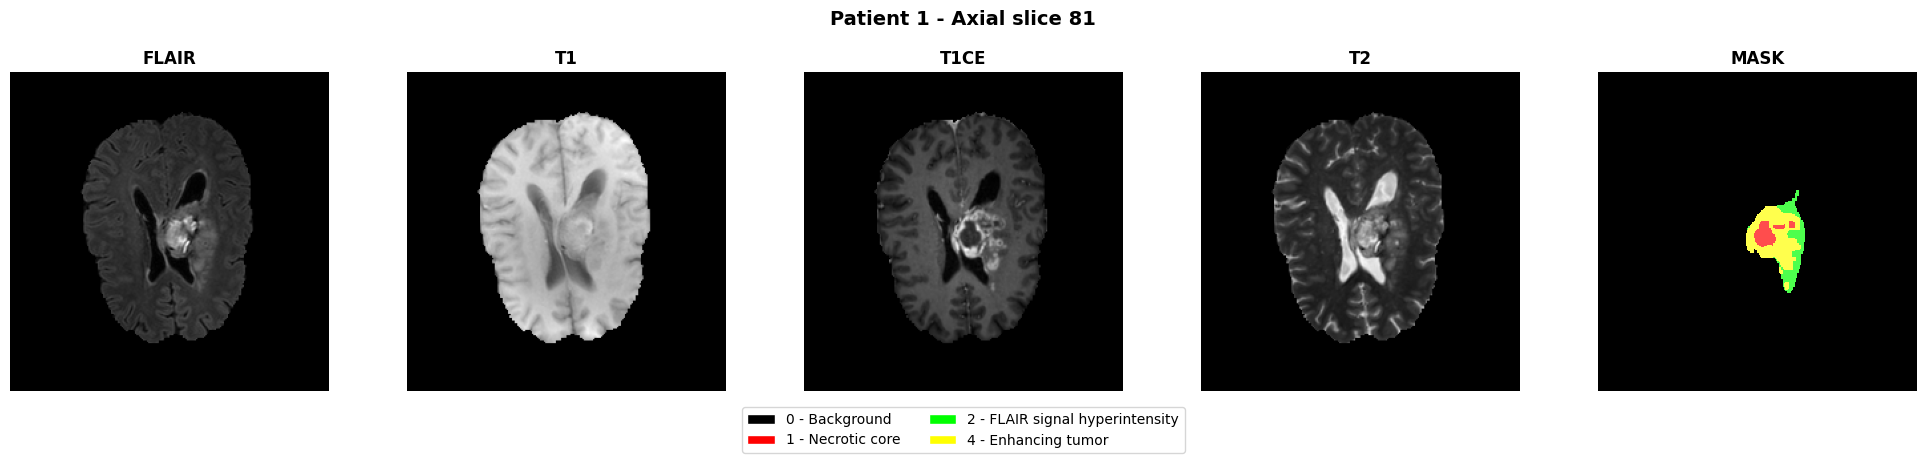

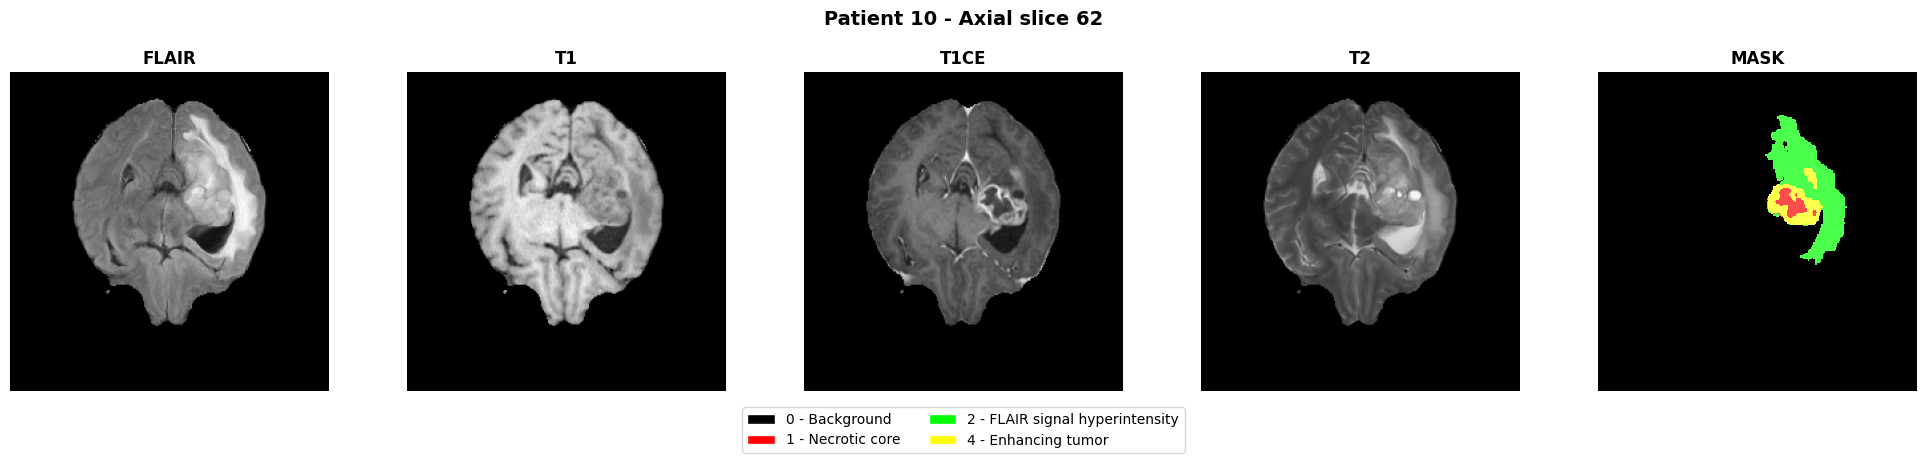

In [11]:
# ================================================================
# 16. VISUALIZATION WITH SEGMENTATION LABEL LEGEND
# ================================================================
#
# Mask label mapping:
#
#   0 -> Background
#   1 -> Necrotic core
#   2 -> FLAIR signal hyperintensity
#   4 -> Enhancing tumor
#
# The colors are kept fixed across all patients.
# ================================================================

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# ------------------------------------------------
# Fixed colors for segmentation classes
# ------------------------------------------------

LABEL_COLORS = {
    0: "#000000",   # Background - black
    1: "#FF0000",   # Necrotic core - red
    2: "#00FF00",   # FLAIR hyperintensity - green
    4: "#FFFF00"    # Enhancing tumor - yellow
}

LABEL_DESCRIPTIONS = {
    0: "Background",
    1: "Necrotic core",
    2: "FLAIR signal hyperintensity",
    4: "Enhancing tumor"
}


# ------------------------------------------------
# Function to visualize a patient
# ------------------------------------------------

def visualize_patient(
    patient_folder,
    slice_index=None
):

    rows = patient_df[
        patient_df[
            "patient_folder"
        ].astype(str)
        == str(patient_folder)
    ]

    if rows.empty:

        print(
            f"Patient not found: {patient_folder}"
        )

        return

    row = rows.iloc[0]

    images = {}

    # ============================================================
    # Load MRI modalities
    # ============================================================

    for modality in MODALITIES:

        path = row[
            f"{modality}_path"
        ]

        if isinstance(
            path,
            str
        ):

            try:

                images[modality] = (
                    nib.load(path)
                    .get_fdata()
                )

            except Exception as e:

                print(
                    f"Could not load {modality}: {e}"
                )

    # ============================================================
    # Load segmentation mask
    # ============================================================

    mask_path = row[
        "MASK_path"
    ]

    if isinstance(
        mask_path,
        str
    ):

        try:

            images["MASK"] = (
                nib.load(mask_path)
                .get_fdata()
            )

        except Exception as e:

            print(
                f"Could not load mask: {e}"
            )

    if not images:

        print(
            "No readable images."
        )

        return

    # ============================================================
    # Reference image
    # ============================================================

    reference = images.get(
        "FLAIR",
        next(iter(images.values()))
    )

    if reference.ndim != 3:

        print(
            "Unexpected reference shape:",
            reference.shape
        )

        return

    # ============================================================
    # Select slice
    # ============================================================

    if slice_index is None:

        slice_index = (
            reference.shape[2] // 2
        )

    if not (
        0 <= slice_index
        < reference.shape[2]
    ):

        raise ValueError(
            f"Invalid slice index: {slice_index}"
        )

    # ============================================================
    # Figure
    # ============================================================

    fig, axes = plt.subplots(
        1,
        len(images),
        figsize=(
            4 * len(images),
            4.5
        )
    )

    if len(images) == 1:

        axes = [axes]

    # ============================================================
    # Plot images
    # ============================================================

    for ax, (name, volume) in zip(
        axes,
        images.items()
    ):

        if volume.ndim != 3:

            ax.set_title(
                f"{name} - invalid dimensions"
            )

            ax.axis("off")

            continue

        if volume.shape != reference.shape:

            ax.set_title(
                f"{name} - different shape"
            )

            ax.axis("off")

            continue

        slice_data = np.rot90(
            volume[
                :,
                :,
                slice_index
            ]
        )

        # --------------------------------------------------------
        # MRI
        # --------------------------------------------------------

        if name != "MASK":

            ax.imshow(
                slice_data,
                cmap="gray"
            )

        # --------------------------------------------------------
        # Segmentation mask
        # --------------------------------------------------------

        else:

            # Create transparent background
            # and fixed colors for the labels.

            mask_display = np.zeros(
                slice_data.shape,
                dtype=np.uint8
            )

            # Original stored labels:
            #
            # 0 = background
            # 1 = necrotic
            # 2 = FLAIR hyperintensity
            # 4 = enhancing tumor
            #
            # We keep these values unchanged for display.

            mask_display[
                slice_data == 1
            ] = 1

            mask_display[
                slice_data == 2
            ] = 2

            mask_display[
                slice_data == 4
            ] = 4

            # ----------------------------------------------------
            # Build transparent custom colormap
            # ----------------------------------------------------

            # Index:
            # 0 -> black
            # 1 -> red
            # 2 -> green
            # 3 -> yellow
            #
            # We first remap 4 -> 3 for the colormap.

            display_mask = np.zeros(
                mask_display.shape,
                dtype=np.uint8
            )

            display_mask[
                mask_display == 1
            ] = 1

            display_mask[
                mask_display == 2
            ] = 2

            display_mask[
                mask_display == 4
            ] = 3

            cmap = ListedColormap([
                (0, 0, 0, 1),  # background - black
                (1, 0, 0, 0.70),  # necrotic - red
                (0, 1, 0, 0.70),  # FLAIR - green
                (1, 1, 0, 0.70)   # enhancing - yellow
            ])

            ax.imshow(
                display_mask,
                cmap=cmap,
                interpolation="nearest",
                vmin=0,
                vmax=3
            )

        ax.set_title(
            name,
            fontsize=12,
            fontweight="bold"
        )

        ax.axis("off")

    # ============================================================
    # Legend
    # ============================================================

    legend_elements = [

        Patch(
            facecolor=LABEL_COLORS[0],
            edgecolor="white",
            label="0 - Background"
        ),

        Patch(
            facecolor=LABEL_COLORS[1],
            edgecolor="white",
            label="1 - Necrotic core"
        ),

        Patch(
            facecolor=LABEL_COLORS[2],
            edgecolor="white",
            label="2 - FLAIR signal hyperintensity"
        ),

        Patch(
            facecolor=LABEL_COLORS[4],
            edgecolor="white",
            label="4 - Enhancing tumor"
        )
    ]

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, -0.02),
        frameon=True,
        fontsize=10
    )

    # ============================================================
    # Title
    # ============================================================

    plt.suptitle(
        f"Patient {patient_folder}"
        f" - Axial slice {slice_index}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0.10, 1, 0.95]
    )

    plt.show()


# ================================================================
# 17. VISUALIZE A SLICE CONTAINING TUMOR
# ================================================================

def find_tumor_slice(
    mask_path
):

    mask = nib.load(
        mask_path
    ).get_fdata()

    tumor = (
        mask != 0
    )

    slice_counts = (
        tumor.sum(axis=(0, 1))
    )

    if slice_counts.max() == 0:

        return (
            mask.shape[2] // 2
        )

    return int(
        np.argmax(
            slice_counts
        )
    )


def visualize_tumor_slice(
    patient_folder
):

    row = patient_df[
        patient_df[
            "patient_folder"
        ].astype(str)
        == str(patient_folder)
    ]

    if row.empty:
        print("Patient not found.")
        return

    row = row.iloc[0]

    mask_path = row[
        "MASK_path"
    ]

    if not isinstance(
        mask_path,
        str
    ):

        print(
            "No mask available."
        )

        return

    slice_idx = find_tumor_slice(
        mask_path
    )

    visualize_patient(
        patient_folder,
        slice_index=slice_idx
    )


# ================================================================
# Example: visualize 2 patients with available segmentation
# ================================================================

visualization_patients = patient_df[
    patient_df["MASK"].astype(bool)
    &
    patient_df["ALL_MODALITIES_PRESENT"].astype(bool)
].copy()

print(
    f"Patients available for visualization: "
    f"{len(visualization_patients)}"
)

for patient_folder in (
    visualization_patients["patient_folder"].head(2)
):
    
    visualize_tumor_slice(
        patient_folder
    )

In [13]:
# ================================================================
# 18. PATIENT-LEVEL TRAIN / VAL / TEST SPLIT
# ================================================================
#
# IMPORTANTE:
#
# Gli split vengono creati a livello di paziente.
# Mai slice-level o patch-level.
#
# TEST:
#   solo pazienti con mask
#
# TRAIN / VAL:
#   pazienti con mask
#
# UNLABELED:
#   pazienti senza mask
#
# Per MAE:
#   TRAIN_MAE = TRAIN + UNLABELED
#
# TEST non viene usato nel MAE.
# ================================================================

# ------------------------------------------------
# Labeled dataset
# ------------------------------------------------

labeled_df = patient_df[
    patient_df["MASK"]
    &
    patient_df[
        "ALL_MODALITIES_PRESENT"
    ]
].copy()

# ------------------------------------------------
# Unlabeled dataset
# ------------------------------------------------

unlabeled_df = patient_df[
    (~patient_df["MASK"])
    &
    patient_df[
        "ALL_MODALITIES_PRESENT"
    ]
].copy()

print(
    "Labeled patients with all 4 MRI:",
    len(labeled_df)
)

print(
    "Unlabeled patients with all 4 MRI:",
    len(unlabeled_df)
)

# ------------------------------------------------
# Create TEST
# ------------------------------------------------

try:

    train_val_df, test_df = train_test_split(
        labeled_df,
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=labeled_df[
            COHORT_COLUMN
        ]
    )

except ValueError:

    print(
        "WARNING: stratification by Cohort ID "
        "not possible. Using random patient-level split."
    )

    train_val_df, test_df = train_test_split(
        labeled_df,
        test_size=TEST_SIZE,
        random_state=SEED
    )

# ------------------------------------------------
# Validation fraction relative to TRAIN+VAL
# ------------------------------------------------

relative_val_size = (
    VAL_SIZE /
    (1 - TEST_SIZE)
)

try:

    train_df, val_df = train_test_split(
        train_val_df,
        test_size=relative_val_size,
        random_state=SEED,
        stratify=train_val_df[
            COHORT_COLUMN
        ]
    )

except ValueError:

    print(
        "WARNING: stratification by Cohort ID "
        "not possible for train/validation split."
    )

    train_df, val_df = train_test_split(
        train_val_df,
        test_size=relative_val_size,
        random_state=SEED
    )

# ------------------------------------------------
# Add split labels
# ------------------------------------------------

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()
unlabeled_df = unlabeled_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"
unlabeled_df["split"] = "unlabeled"

# ------------------------------------------------
# Training pool for MAE
# ------------------------------------------------
#
# Include:
#   labeled training patients
#   unlabeled patients
#
# Exclude:
#   validation
#   test
#
# ------------------------------------------------

mae_train_df = pd.concat(
    [
        train_df,
        unlabeled_df
    ],
    ignore_index=True
)

mae_train_df["mae_usage"] = (
    "self_supervised_train"
)

print("\nSplit sizes:")

print(
    "TRAIN:",
    len(train_df)
)

print(
    "VALIDATION:",
    len(val_df)
)

print(
    "TEST:",
    len(test_df)
)

print(
    "UNLABELED:",
    len(unlabeled_df)
)

print(
    "MAE training pool:",
    len(mae_train_df)
)

# ================================================================
# 19. SPLIT INTEGRITY CHECK
# ================================================================

split_sets = {

    "train":
        set(train_df["patient_key"]),

    "validation":
        set(val_df["patient_key"]),

    "test":
        set(test_df["patient_key"]),

    "unlabeled":
        set(unlabeled_df["patient_key"])
}

split_names = list(
    split_sets.keys()
)

overlap_found = False

for i in range(
    len(split_names)
):

    for j in range(
        i + 1,
        len(split_names)
    ):

        a = split_names[i]
        b = split_names[j]

        overlap = (
            split_sets[a]
            &
            split_sets[b]
        )

        if overlap:

            overlap_found = True

            print(
                f"OVERLAP: {a} vs {b}: "
                f"{len(overlap)} patients"
            )

if not overlap_found:

    print(
        "✓ No patient overlap between splits."
    )

# ------------------------------------------------
# Check MAE leakage
# ------------------------------------------------

mae_ids = set(
    mae_train_df[
        "patient_key"
    ]
)

test_ids = set(
    test_df[
        "patient_key"
    ]
)

mae_test_overlap = (
    mae_ids &
    test_ids
)

print(
    "\nMAE pool / TEST overlap:",
    len(mae_test_overlap)
)

if len(mae_test_overlap) == 0:

    print(
        "✓ TEST patients are not used for MAE."
    )

else:

    print(
        "WARNING: MAE leakage detected!"
    )

# ================================================================
# 20. COHORT DISTRIBUTION ACROSS SPLITS
# ================================================================

split_df = pd.concat(
    [
        train_df,
        val_df,
        test_df,
        unlabeled_df
    ],
    ignore_index=True
)

cohort_split_summary = (
    split_df
    .groupby(
        [
            COHORT_COLUMN,
            "split"
        ],
        dropna=False
    )
    .size()
    .unstack(
        fill_value=0
    )
)

display(
    cohort_split_summary
)

print(
    "\nThis table should be checked before training."
)

Labeled patients with all 4 MRI: 1180
Unlabeled patients with all 4 MRI: 204

Split sizes:
TRAIN: 826
VALIDATION: 177
TEST: 177
UNLABELED: 204
MAE training pool: 1030
✓ No patient overlap between splits.

MAE pool / TEST overlap: 0
✓ TEST patients are not used for MAE.


split,test,train,unlabeled,validation
Cohort ID,,,,
1,0,3,0,1
2,5,23,4,5
3,4,17,3,4
4,52,244,53,52
5,14,66,29,14
6,10,45,43,10
7,35,163,34,35
8,57,265,38,56



This table should be checked before training.


In [14]:
# ================================================================
# 21. BUILD FINAL TRAINING MANIFEST
# ================================================================
#
# Il training notebook dovrà leggere soltanto questo CSV.
#
# Contiene:
#   - patient ID
#   - center
#   - split
#   - path delle 4 MRI
#   - mask path
#   - disponibilità delle modalità
#   - flag labeled/unlabeled
#
# ================================================================

manifest = patient_df.copy()

# ------------------------------------------------
# Assign split
# ------------------------------------------------

split_lookup = {}

for _, row in train_df.iterrows():
    split_lookup[row["patient_key"]] = "train"

for _, row in val_df.iterrows():
    split_lookup[row["patient_key"]] = "validation"

for _, row in test_df.iterrows():
    split_lookup[row["patient_key"]] = "test"

for _, row in unlabeled_df.iterrows():
    split_lookup[row["patient_key"]] = "unlabeled"

manifest["split"] = (
    manifest["patient_key"]
    .map(split_lookup)
)

# ------------------------------------------------
# Labeled / unlabeled flag
# ------------------------------------------------

manifest["is_labeled"] = (
    manifest["MASK"]
    &
    manifest[
        "ALL_MODALITIES_PRESENT"
    ]
)

manifest["is_unlabeled"] = (
    (~manifest["MASK"])
    &
    manifest[
        "ALL_MODALITIES_PRESENT"
    ]
)

# ------------------------------------------------
# MAE usage
# ------------------------------------------------

manifest["use_for_mae"] = (
    manifest["split"]
    .isin(
        [
            "train",
            "unlabeled"
        ]
    )
    &
    manifest[
        "ALL_MODALITIES_PRESENT"
    ]
)

# ------------------------------------------------
# Segmentation usage
# ------------------------------------------------

manifest["use_for_segmentation"] = (
    manifest["split"]
    .isin(
        [
            "train",
            "validation",
            "test"
        ]
    )
    &
    manifest["is_labeled"]
)

# ------------------------------------------------
# Keep useful columns first
# ------------------------------------------------

manifest_columns = [

    "patient_key",
    "patient_folder",
    COHORT_COLUMN,

    "split",

    "is_labeled",
    "is_unlabeled",

    "use_for_mae",
    "use_for_segmentation",

    "FLAIR",
    "T1",
    "T1CE",
    "T2",

    "ALL_MODALITIES_PRESENT",

    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",

    "MASK",
    "MASK_path",

    "MRI_COMBINATION"
]

manifest = manifest[
    [
        col
        for col in manifest_columns
        if col in manifest.columns
    ]
].copy()

# ------------------------------------------------
# Sort by patient ID
# ------------------------------------------------

manifest = manifest.sort_values(
    "patient_key"
).reset_index(
    drop=True
)

print(
    "Final manifest shape:",
    manifest.shape
)

display(
    manifest.head(10)
)

# ================================================================
# 22. MAE MANIFEST
# ================================================================

mae_manifest = manifest[
    manifest["use_for_mae"]
].copy()

print(
    "Patients available for MAE:",
    len(mae_manifest)
)

print(
    "\nBreakdown:"
)

print(
    mae_manifest[
        "split"
    ].value_counts()
)

display(
    mae_manifest.head()
)

# ================================================================
# 23. SEGMENTATION MANIFEST
# ================================================================

segmentation_manifest = manifest[
    manifest[
        "use_for_segmentation"
    ]
].copy()

print(
    "Patients available for supervised segmentation:",
    len(segmentation_manifest)
)

print(
    "\nSplit:"
)

print(
    segmentation_manifest[
        "split"
    ].value_counts()
)

display(
    segmentation_manifest.head()
)

Final manifest shape: (1384, 20)


,patient_key,patient_folder,Cohort ID,split,is_labeled,is_unlabeled,use_for_mae,use_for_segmentation,FLAIR,T1,T1CE,T2,ALL_MODALITIES_PRESENT,FLAIR_path,T1_path,T1CE_path,T2_path,MASK,MASK_path,MRI_COMBINATION
0,1,1,1,validation,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
1,10,10,2,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
2,1000,1000,8,test,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
3,1001,1001,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
4,1002,1002,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
5,1003,1003,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
6,1004,1004,8,test,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
7,1005,1005,8,validation,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
8,1006,1006,8,validation,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
9,1007,1007,8,test,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2


Patients available for MAE: 1030

Breakdown:
split
train        826
unlabeled    204
Name: count, dtype: int64


,patient_key,patient_folder,Cohort ID,split,is_labeled,is_unlabeled,use_for_mae,use_for_segmentation,FLAIR,T1,T1CE,T2,ALL_MODALITIES_PRESENT,FLAIR_path,T1_path,T1CE_path,T2_path,MASK,MASK_path,MRI_COMBINATION
1,10,10,2,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
3,1001,1001,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
4,1002,1002,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
5,1003,1003,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
10,1008,1008,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2


Patients available for supervised segmentation: 1180

Split:
split
train         826
validation    177
test          177
Name: count, dtype: int64


,patient_key,patient_folder,Cohort ID,split,is_labeled,is_unlabeled,use_for_mae,use_for_segmentation,FLAIR,T1,T1CE,T2,ALL_MODALITIES_PRESENT,FLAIR_path,T1_path,T1CE_path,T2_path,MASK,MASK_path,MRI_COMBINATION
0,1,1,1,validation,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
1,10,10,2,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
2,1000,1000,8,test,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
3,1001,1001,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
4,1002,1002,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2


In [16]:
# ================================================================
# 24. EXPORT DATASET REPORTS
# ================================================================

print("Exporting reports...\n")

exports = {

    # Main patient inventory
    "patient_inventory.csv":
        patient_df,

    # All discovered files
    "file_inventory.csv":
        files_df,

    # General availability
    "availability_summary.csv":
        availability_df,

    # MRI combinations
    "modality_combinations.csv":
        combination_summary,

    "modality_mask_combinations.csv":
        combination_mask_summary,

    # Centers
    "cohort_distribution.csv":
        cohort_distribution,

    "cohort_availability.csv":
        center_availability,

    # Masks
    "mask_inspection.csv":
        mask_df,

    "label_distribution.csv":
        label_distribution_df,

    # Duplicates / errors
    "multiple_file_candidates.csv":
        duplicate_files_df,

    "empty_files.csv":
        empty_df,

    # Training manifests
    "training_manifest.csv":
        manifest,

    "segmentation_manifest.csv":
        segmentation_manifest,

    "mae_manifest.csv":
        mae_manifest,

    # Fixed splits
    "train_patients.csv":
        train_df,

    "validation_patients.csv":
        val_df,

    "test_patients.csv":
        test_df,

    "unlabeled_patients.csv":
        unlabeled_df
}

for filename, dataframe in exports.items():

    dataframe.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

# ------------------------------------------------
# JSON summary
# ------------------------------------------------

summary = {

    "total_patient_folders":
        int(len(patient_df)),

    "patients_with_FLAIR":
        int(patient_df["FLAIR"].sum()),

    "patients_with_T1":
        int(patient_df["T1"].sum()),

    "patients_with_T1CE":
        int(patient_df["T1CE"].sum()),

    "patients_with_T2":
        int(patient_df["T2"].sum()),

    "patients_with_all_four_MRI":
        int(
            patient_df[
                "ALL_MODALITIES_PRESENT"
            ].sum()
        ),

    "patients_with_mask":
        int(
            patient_df[
                "MASK"
            ].sum()
        ),

    "complete_patients":
        int(
            patient_df[
                "COMPLETE_PATIENT"
            ].sum()
        ),

    "labeled_training_patients":
        int(len(train_df)),

    "validation_patients":
        int(len(val_df)),

    "test_patients":
        int(len(test_df)),

    "unlabeled_training_patients":
        int(len(unlabeled_df)),

    "mae_training_patients":
        int(len(mae_manifest)),

    "number_of_centers":
        int(
            metadata[
                COHORT_COLUMN
            ].nunique(
                dropna=True
            )
        ),

    "observed_mask_labels":
        sorted(
            global_label_counts.keys()
        ),

    "label_mapping":
        LABEL_MAPPING,

    "seed":
        SEED
}

with open(
    OUTPUT_DIR /
    "dataset_summary.json",
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4,
        default=str
    )

print(
    "\n✓ All reports exported."
)

# ================================================================
# 25. FINAL CHECK
# ================================================================

print("\n" + "=" * 70)
print("PHASE 1 COMPLETED")
print("=" * 70)

print("\nDATASET")
print(
    "Total patients:",
    len(patient_df)
)

print(
    "Complete MRI + mask:",
    int(
        patient_df[
            "COMPLETE_PATIENT"
        ].sum()
    )
)

print(
    "Unlabeled with all 4 MRI:",
    len(unlabeled_df)
)

print("\nSPLITS")
print(
    "Train:",
    len(train_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Test:",
    len(test_df)
)

print(
    "MAE pool:",
    len(mae_manifest)
)

print("\nLABELS")
print(
    "Stored labels:",
    sorted(
        global_label_counts.keys()
    )
)

print("\nOUTPUT DIRECTORY")
print(
    OUTPUT_DIR
)

print("\nGenerated files:")

for file in sorted(
    OUTPUT_DIR.iterdir()
):

    print(
        " -",
        file.name
    )

print("\n" + "=" * 70)

print(
    "Ready for the separate training notebook."
)

print("=" * 70)

Exporting reports...


✓ All reports exported.

PHASE 1 COMPLETED

DATASET
Total patients: 1384
Complete MRI + mask: 1180
Unlabeled with all 4 MRI: 204

SPLITS
Train: 826
Validation: 177
Test: 177
MAE pool: 1030

LABELS
Stored labels: [0.0, 1.0, 2.0, 4.0]

OUTPUT DIRECTORY
/kaggle/working/phase1_reports

Generated files:
 - availability_summary.csv
 - cohort_availability.csv
 - cohort_distribution.csv
 - dataset_summary.json
 - empty_files.csv
 - file_inventory.csv
 - label_distribution.csv
 - mae_manifest.csv
 - mask_inspection.csv
 - modality_combinations.csv
 - modality_mask_combinations.csv
 - multiple_file_candidates.csv
 - patient_inventory.csv
 - segmentation_manifest.csv
 - test_patients.csv
 - train_patients.csv
 - training_manifest.csv
 - unlabeled_patients.csv
 - validation_patients.csv

Ready for the separate training notebook.
